In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

## 1. Data Analysis and visualization of last 365 days

In [2]:
df365 = pd.read_csv('cleaned_HandigaunLast365days.csv')
df365

,location_id,location_name,parameter,value,unit,datetimeLocal,timezone,latitude,longitude,owner_name,provider,date,time
0,2848864,"Dabali, Handigaun",pm25,56.245883,µg/m³,2025-10-12 06:45:00+05:45,Asia/Kathmandu,27.681891,85.287078,Unknown Person,AirGradient,2025-10-12,06:45:00
1,2848864,"Dabali, Handigaun",pm25,57.654112,µg/m³,2025-10-12 07:45:00+05:45,Asia/Kathmandu,27.681891,85.287078,Unknown Person,AirGradient,2025-10-12,07:45:00
2,2848864,"Dabali, Handigaun",pm25,42.654445,µg/m³,2025-10-12 08:45:00+05:45,Asia/Kathmandu,27.681891,85.287078,Unknown Person,AirGradient,2025-10-12,08:45:00
3,2848864,"Dabali, Handigaun",pm25,46.807793,µg/m³,2025-10-12 09:45:00+05:45,Asia/Kathmandu,27.681891,85.287078,Unknown Person,AirGradient,2025-10-12,09:45:00
4,2848864,"Dabali, Handigaun",pm25,37.498016,µg/m³,2025-10-12 10:45:00+05:45,Asia/Kathmandu,27.681891,85.287078,Unknown Person,AirGradient,2025-10-12,10:45:00
...,...,...,...,...,...,...,...,...,...,...,...,...,...
995,2848864,"Dabali, Handigaun",pm25,46.697024,µg/m³,2025-11-25 17:45:00+05:45,Asia/Kathmandu,27.681891,85.287078,Unknown Person,AirGradient,2025-11-25,17:45:00
996,2848864,"Dabali, Handigaun",pm25,44.546131,µg/m³,2025-11-25 18:45:00+05:45,Asia/Kathmandu,27.681891,85.287078,Unknown Person,AirGradient,2025-11-25,18:45:00
997,2848864,"Dabali, Handigaun",pm25,47.059048,µg/m³,2025-11-25 19:45:00+05:45,Asia/Kathmandu,27.681891,85.287078,Unknown Person,AirGradient,2025-11-25,19:45:00
998,2848864,"Dabali, Handigaun",pm25,60.145833,µg/m³,2025-11-25 20:45:00+05:45,Asia/Kathmandu,27.681891,85.287078,Unknown Person,AirGradient,2025-11-25,20:45:00


In [3]:
df365['date'].unique()

<ArrowStringArray>
['2025-10-12', '2025-10-13', '2025-10-14', '2025-10-15', '2025-10-16',
 '2025-10-17', '2025-10-18', '2025-10-19', '2025-10-20', '2025-10-22',
 '2025-10-23', '2025-10-24', '2025-10-25', '2025-10-26', '2025-10-27',
 '2025-10-28', '2025-10-29', '2025-10-30', '2025-10-31', '2025-11-01',
 '2025-11-02', '2025-11-03', '2025-11-04', '2025-11-05', '2025-11-06',
 '2025-11-07', '2025-11-08', '2025-11-09', '2025-11-10', '2025-11-11',
 '2025-11-12', '2025-11-13', '2025-11-14', '2025-11-15', '2025-11-16',
 '2025-11-17', '2025-11-18', '2025-11-19', '2025-11-20', '2025-11-21',
 '2025-11-22', '2025-11-23', '2025-11-24', '2025-11-25']
Length: 44, dtype: str

### Aggrigating hourly data to daily means, and filling only short gaps(1 to 2 days) by interpolation

In [4]:
# 1. Load hourly data observations
hourly = df365

# Ensure date and PM2.5 values have appropriate types
hourly['date'] = pd.to_datetime(hourly['date'])
hourly['value'] = pd.to_numeric(hourly['value'], errors='coerce')

In [5]:
# 2-3. Aggrigate available hourly PM2.5 values to daily means
daily = (
    hourly.dropna(subset=['date', 'value'])
    .groupby('date', as_index=True)
    .agg(
        pm25_daily_mean_ug_m3=('date', 'mean'),
        hourly_observation_count=('value', 'count'),
    )
    .sort_index()
)

In [6]:
# 4. Include every calendar day in the observed date range
all_days = pd.date_range(daily.index.min(), daily.index.max(), freq="D")
daily = daily.reindex(all_days)
daily.index.name = "date"

In [7]:
# Mark original observed daily means
daily["fill_method"] = "observed"
daily.loc[daily["pm25_daily_mean_ug_m3"].isna(), "fill_method"] = "missing_long_gap"

In [8]:
# 5–6. Identify missing runs and interpolate only 1–2 day gaps
missing = daily["pm25_daily_mean_ug_m3"].isna()
run_id = missing.ne(missing.shift()).cumsum()

for _, run_mask in missing.groupby(run_id):
    if not run_mask.iloc[0]:
        continue  # This run contains observed data, not missing data

    gap_dates = run_mask.index[run_mask]
    gap_length = len(gap_dates)

    # Only fill gaps lasting one or two days and bounded by observed values
    if gap_length in (1, 2):
        first_pos = daily.index.get_loc(gap_dates[0])
        last_pos = daily.index.get_loc(gap_dates[-1])

        has_left_neighbor = first_pos > 0
        has_right_neighbor = last_pos < len(daily.index) - 1

        if has_left_neighbor and has_right_neighbor:
            left_value = daily.iloc[first_pos - 1]["pm25_daily_mean_ug_m3"]
            right_value = daily.iloc[last_pos + 1]["pm25_daily_mean_ug_m3"]

            if pd.notna(left_value) and pd.notna(right_value):
                # Linear interpolation between the two surrounding daily means
                interpolated = daily["pm25_daily_mean_ug_m3"].interpolate(
                    method="linear",
                    limit=2,
                    limit_area="inside",
                )
                daily.loc[gap_dates, "pm25_daily_mean_ug_m3"] = interpolated.loc[gap_dates]
                daily.loc[gap_dates, "hourly_observation_count"] = 0
                daily.loc[gap_dates, "fill_method"] = "linear_interpolation"

In [9]:
# 7. Write a tidy CSV
daily = daily.reset_index()
daily["date"] = daily["date"].dt.strftime("%Y-%m-%d")

In [10]:
daily

,date,pm25_daily_mean_ug_m3,hourly_observation_count,fill_method
0,2025-10-12,2025-10-12,18.0,observed
1,2025-10-13,2025-10-13,24.0,observed
2,2025-10-14,2025-10-14,24.0,observed
3,2025-10-15,2025-10-15,24.0,observed
4,2025-10-16,2025-10-16,24.0,observed
5,2025-10-17,2025-10-17,24.0,observed
6,2025-10-18,2025-10-18,24.0,observed
7,2025-10-19,2025-10-19,24.0,observed
8,2025-10-20,2025-10-20,11.0,observed
9,2025-10-21,2025-10-21,0.0,linear_interpolation


In [11]:
daily.columns

Index(['date', 'pm25_daily_mean_ug_m3', 'hourly_observation_count',
       'fill_method'],
      dtype='str')

### Plotting daily aggrigate value

/tmp/ipykernel_15421/1174245757.py:8: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  plt.legend()


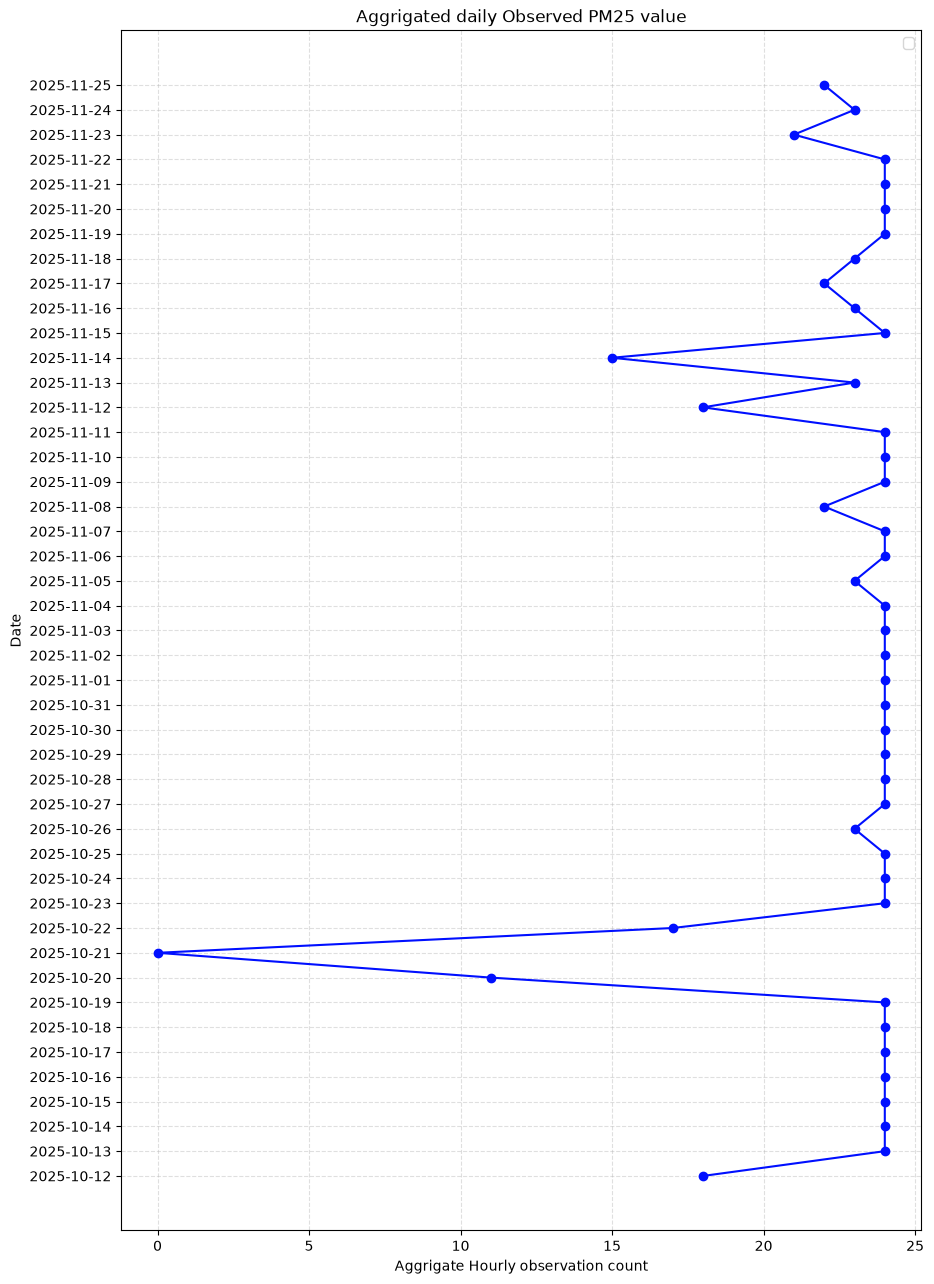

In [12]:
fig = plt.figure(figsize=(10, 15))
ax = fig.add_axes([0.1, 0.1, 0.8, 0.8])
ax.plot(daily['hourly_observation_count'], daily['date'], color ='#000fff', marker='o')
plt.xlabel('Aggrigate Hourly observation count')
plt.ylabel('Date')
plt.title("Aggrigated daily Observed PM25 value")
plt.grid(linestyle='--', alpha=0.4)
plt.legend()
plt.show()